<a href="https://colab.research.google.com/github/EmanFatima-38/Emails-spam/blob/main/Email_spam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving spam_ham_dataset.csv to spam_ham_dataset.csv


In [2]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
print("Libraries loaded")

Libraries loaded


In [3]:
df = pd.read_csv("spam_ham_dataset.csv")
print(df.shape)
df.head()

(5171, 4)


,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\r\n...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see...",0
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re ar...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\r\nthis deal is t...,0


After cleaning: (4993, 2)
label_num
0    3531
1    1462
Name: count, dtype: int64


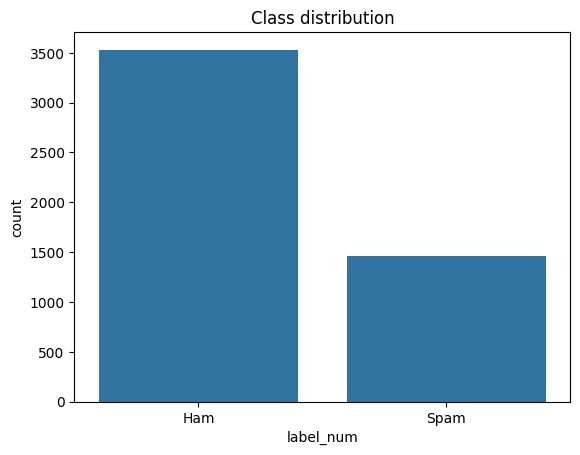

In [4]:
df = df[["text", "label_num"]]
df = df.dropna().drop_duplicates(subset="text")
print("After cleaning:", df.shape)
print(df["label_num"].value_counts())

sns.countplot(x=df["label_num"].map({0: "Ham", 1: "Spam"}))
plt.title("Class distribution"); plt.show()

In [5]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"subject:", " ", text)
    text = re.sub(r"http\S+|www\.\S+", " url ", text)
    text = re.sub(r"\S+@\S+", " email ", text)
    text = re.sub(r"\d+", " number ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    words = [w for w in text.split() if w not in ENGLISH_STOP_WORDS and len(w) > 2]
    return " ".join(words)

df["clean"] = df["text"].apply(clean_text)
print("BEFORE:", df["text"].iloc[0][:200])
print("AFTER :", df["clean"].iloc[0][:200])

BEFORE: Subject: enron methanol ; meter # : 988291
this is a follow up to the note i gave you on monday , 4 / 3 / 00 { preliminary
flow data provided by daren } .
please override pop ' s daily volume { pre
AFTER : enron methanol meter number follow note gave monday number number number preliminary flow data provided daren override pop daily volume presently zero reflect daily activity obtain gas control change 


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label_num"], test_size=0.2, random_state=42, stratify=df["label_num"])

vectorizer = TfidfVectorizer(max_features=30000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr = vectorizer.fit_transform(X_train)
Xte = vectorizer.transform(X_test)
print("Training emails:", Xtr.shape[0], " Test emails:", Xte.shape[0], " Features:", Xtr.shape[1])

Training emails: 3994  Test emails: 999  Features: 30000


                     Accuracy  Precision  Recall      F1
Model                                                   
Naive Bayes             0.967     0.9140  0.9795  0.9456
Logistic Regression     0.985     0.9664  0.9829  0.9746
Linear SVM              0.989     0.9732  0.9898  0.9814


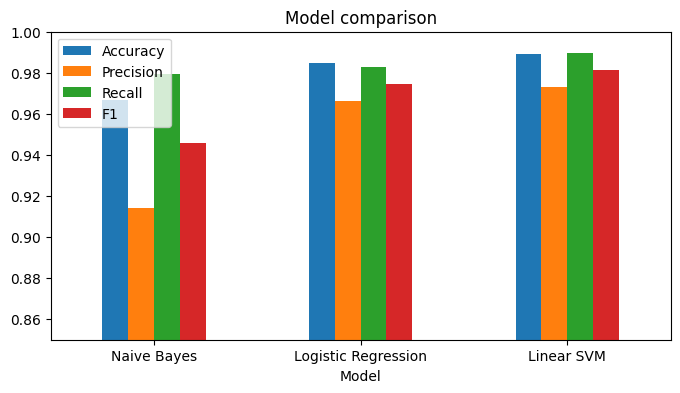

In [7]:
models = {
    "Naive Bayes": MultinomialNB(alpha=0.1),
    "Logistic Regression": LogisticRegression(C=10, max_iter=2000),
    "Linear SVM": LinearSVC(),
}
results = []
for name, model in models.items():
    model.fit(Xtr, y_train)
    y_pred = model.predict(Xte)
    results.append([name, accuracy_score(y_test, y_pred), precision_score(y_test, y_pred),
                    recall_score(y_test, y_pred), f1_score(y_test, y_pred)])

res = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1"]).set_index("Model")
print(res.round(4))
res.plot(kind="bar", figsize=(8, 4)); plt.ylim(0.85, 1); plt.xticks(rotation=0)
plt.title("Model comparison"); plt.show()

Best model: Linear SVM
              precision    recall  f1-score   support

         Ham       1.00      0.99      0.99       706
        Spam       0.97      0.99      0.98       293

    accuracy                           0.99       999
   macro avg       0.98      0.99      0.99       999
weighted avg       0.99      0.99      0.99       999



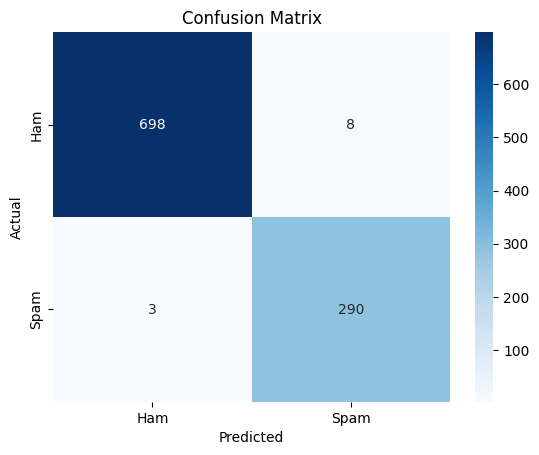

In [8]:
best_name = res["F1"].idxmax()
best = models[best_name]
y_pred = best.predict(Xte)
print("Best model:", best_name)
print(classification_report(y_test, y_pred, target_names=["Ham", "Spam"]))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix"); plt.show()

In [9]:
emails = [
    "Congratulations! You have WON a $1000 gift card. Click here to claim now!",
    "Hi team, the meeting is moved to 3pm tomorrow. Please bring the report.",
    "URGENT: your account is suspended. Verify your password at this link",
    "Can you send me the lecture notes from Monday's class? Thanks.",
]
for e in emails:
    p = best.predict(vectorizer.transform([clean_text(e)]))[0]
    print("SPAM" if p == 1 else "HAM ", "->", e)

SPAM -> Congratulations! You have WON a $1000 gift card. Click here to claim now!
HAM  -> Hi team, the meeting is moved to 3pm tomorrow. Please bring the report.
SPAM -> URGENT: your account is suspended. Verify your password at this link
HAM  -> Can you send me the lecture notes from Monday's class? Thanks.
